In [1]:
import sys
import os

import numpy as np
import pandas as pd

from sklearn.cross_decomposition import CCA

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import hgm_sep as hgm
from models import clm_sep as clm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm_sep' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm_sep.py'>

In [3]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_')
filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path)

path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# data

In [4]:
artificial = True
worm_id = 33

# selection_n = [label for label in traces_gcamp[worm_id].columns if label != '' and label[-1] != '_']
selection_n = ['AVAR', 'AVAL', 'VB02', 'DB01', 'SMDDR', 'RID']
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

dims = 1
dims_generation = 1

In [5]:
discrete_states = discrete_states_gcamp[worm_id][selection_bhl]
eigenworms = eigenworms_gcamp[worm_id]

if artificial:
	(filename,
	 neural_modes,
	 traces_reconstructed,
	 traces_residual,
	 traces,
	 params_,
	 params_cca) = artificializer.artificialize(hgm,
												filenames_gcamp[worm_id],
												traces_gcamp[worm_id].columns,
												eigenworms,
												discrete_states,
												n_dimensions=dims_generation)
else:
	filename = filenames_gcamp[worm_id]
	traces = traces_gcamp[worm_id][selection_n]
	discrete_states = discrete_states_gcamp[worm_id][selection_bhl]

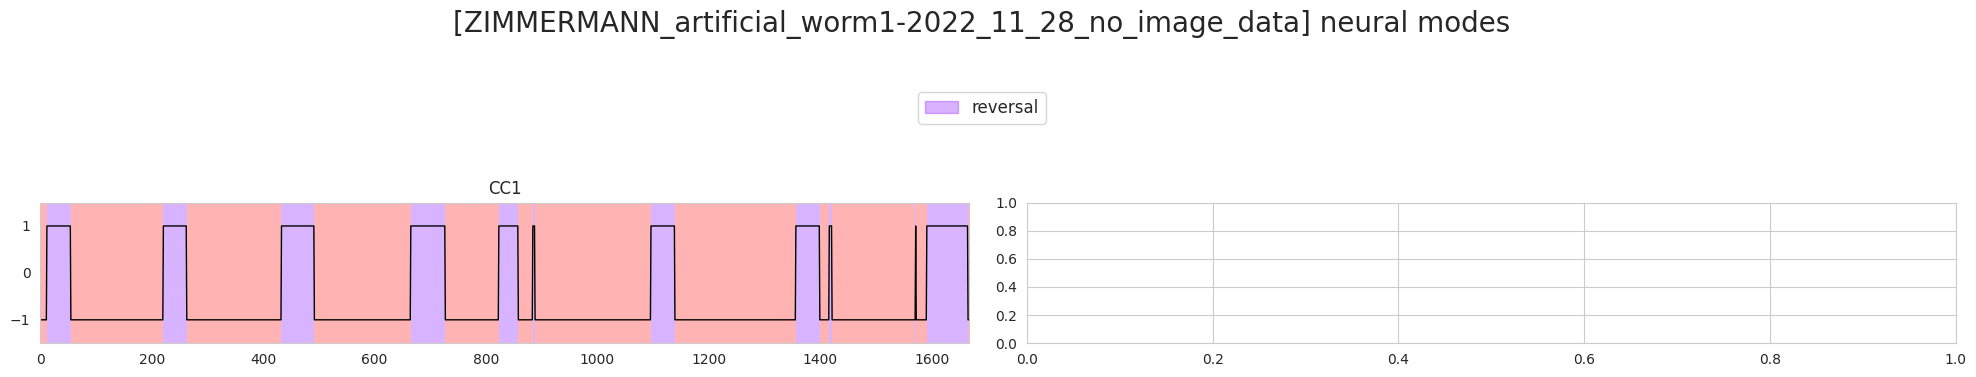

In [6]:
if artificial:
	plot_utils.plot_traces(f'[{filename}] neural modes',
						   neural_modes,
						   discrete_states['REV'],
						   n_plots=dims_generation, plots_per_row=2, ylimits=(-1.5, 1.5))

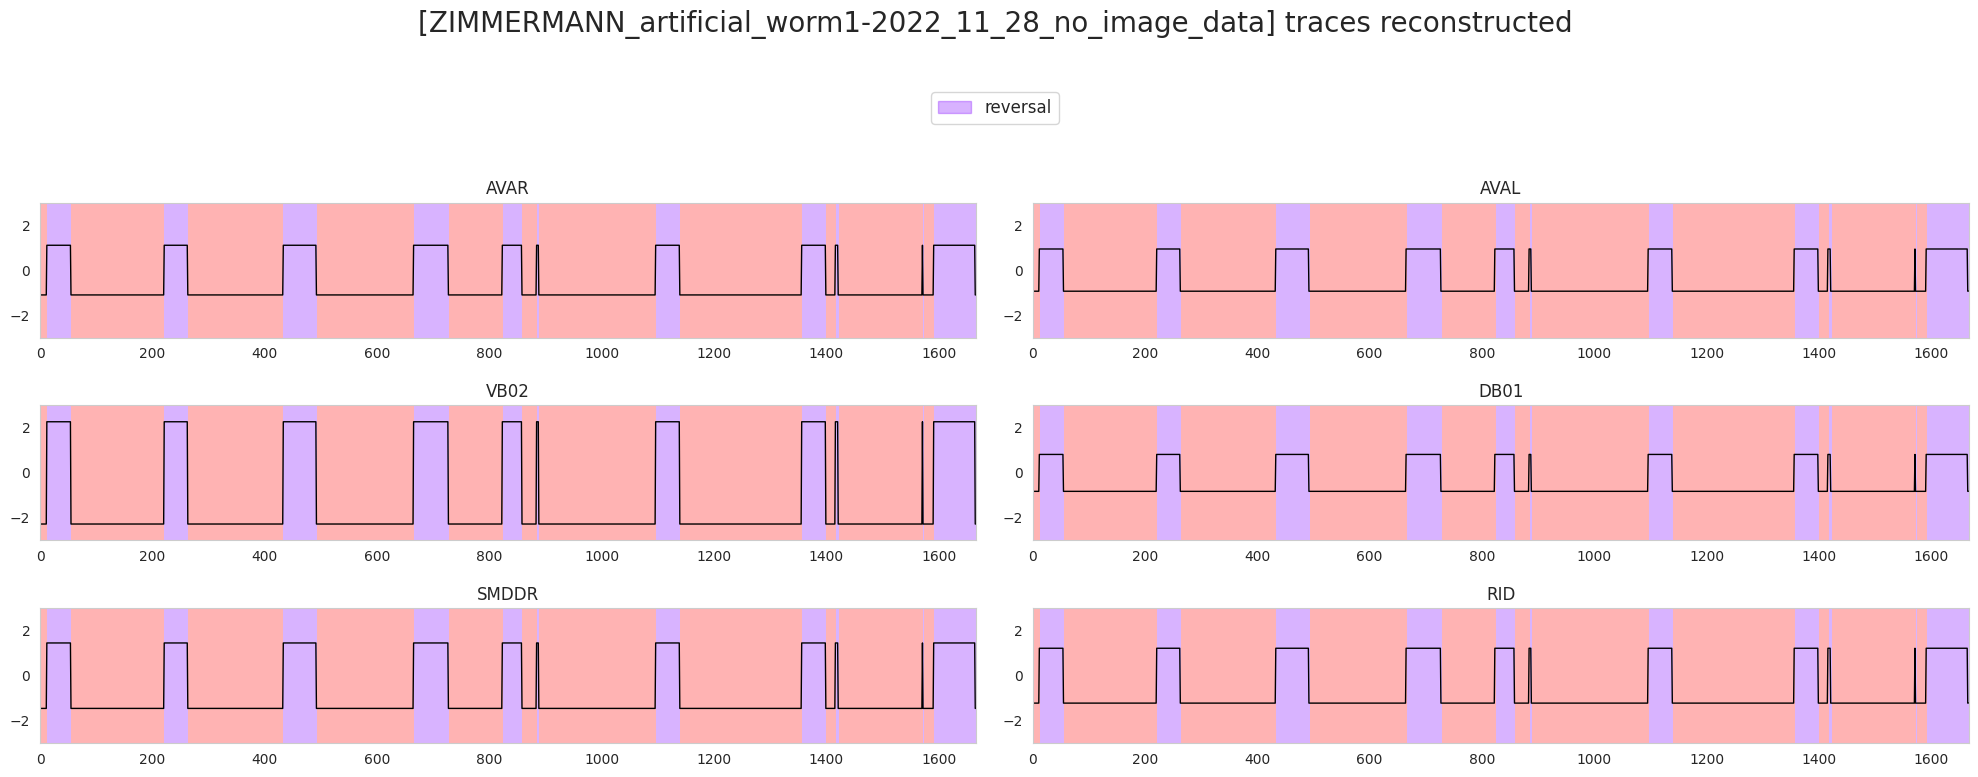

In [7]:
if artificial:
	plot_utils.plot_traces(f'[{filename}] traces reconstructed',
						   traces_reconstructed[selection_n],
						   discrete_states['REV'],
						   n_plots=len(selection_n), plots_per_row=2, ylimits=(-3, 3))

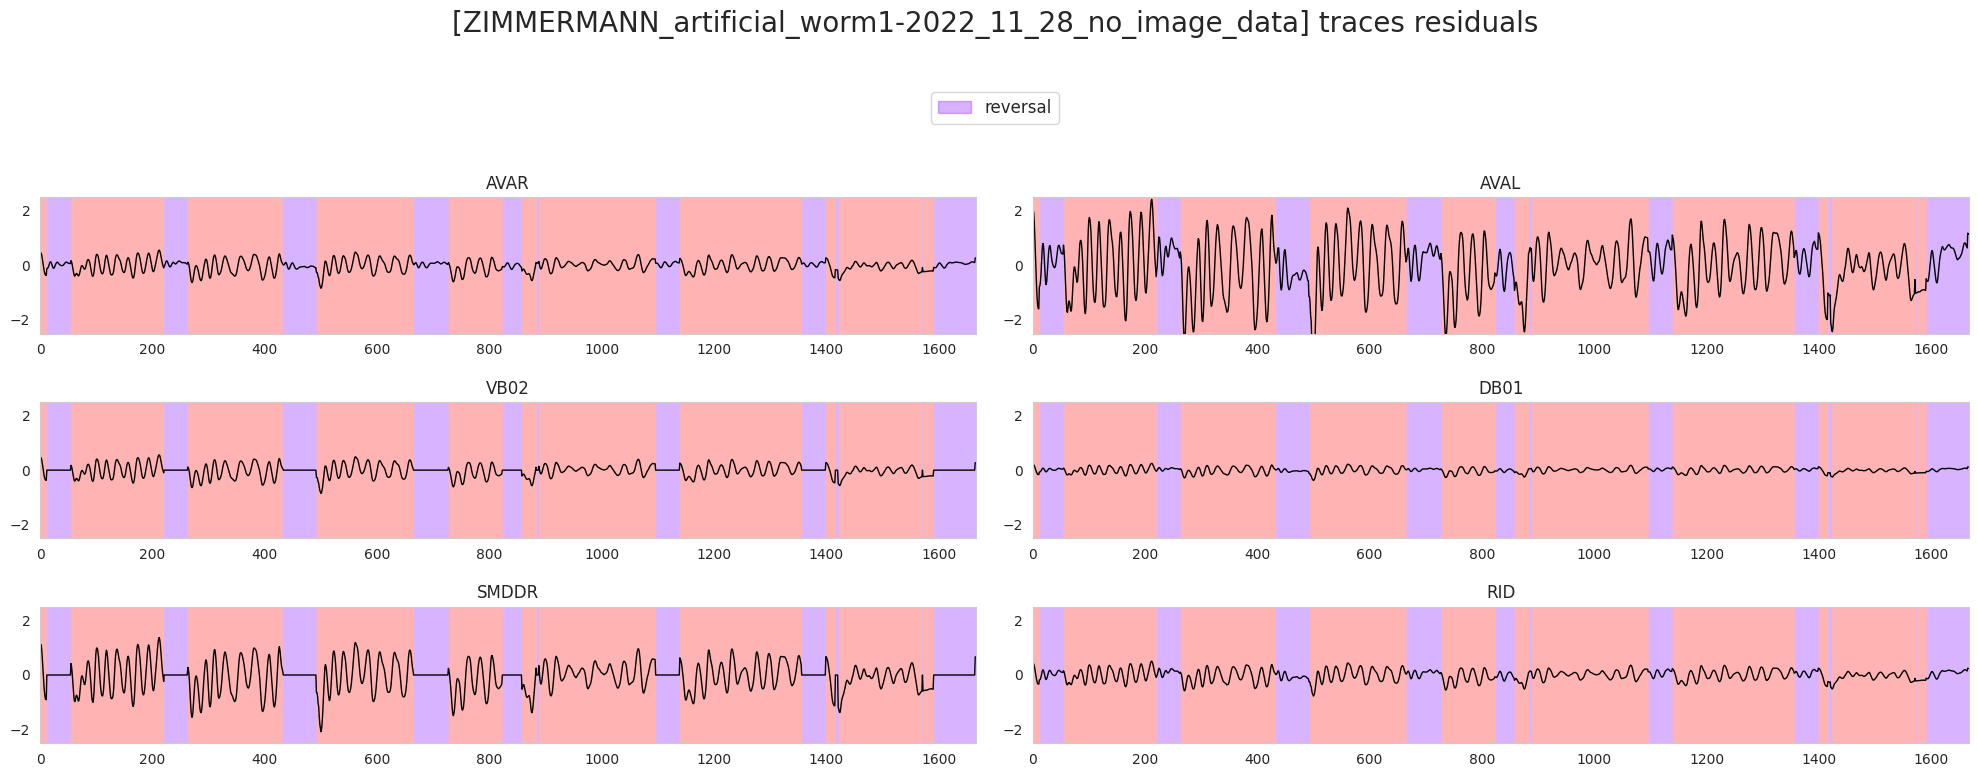

In [8]:
if artificial:
	plot_utils.plot_traces(f'[{filename}] traces residuals',
						   traces_residual[selection_n],
						   discrete_states['REV'],
						   n_plots=len(selection_n), plots_per_row=2, ylimits=(-2.5, 2.5))

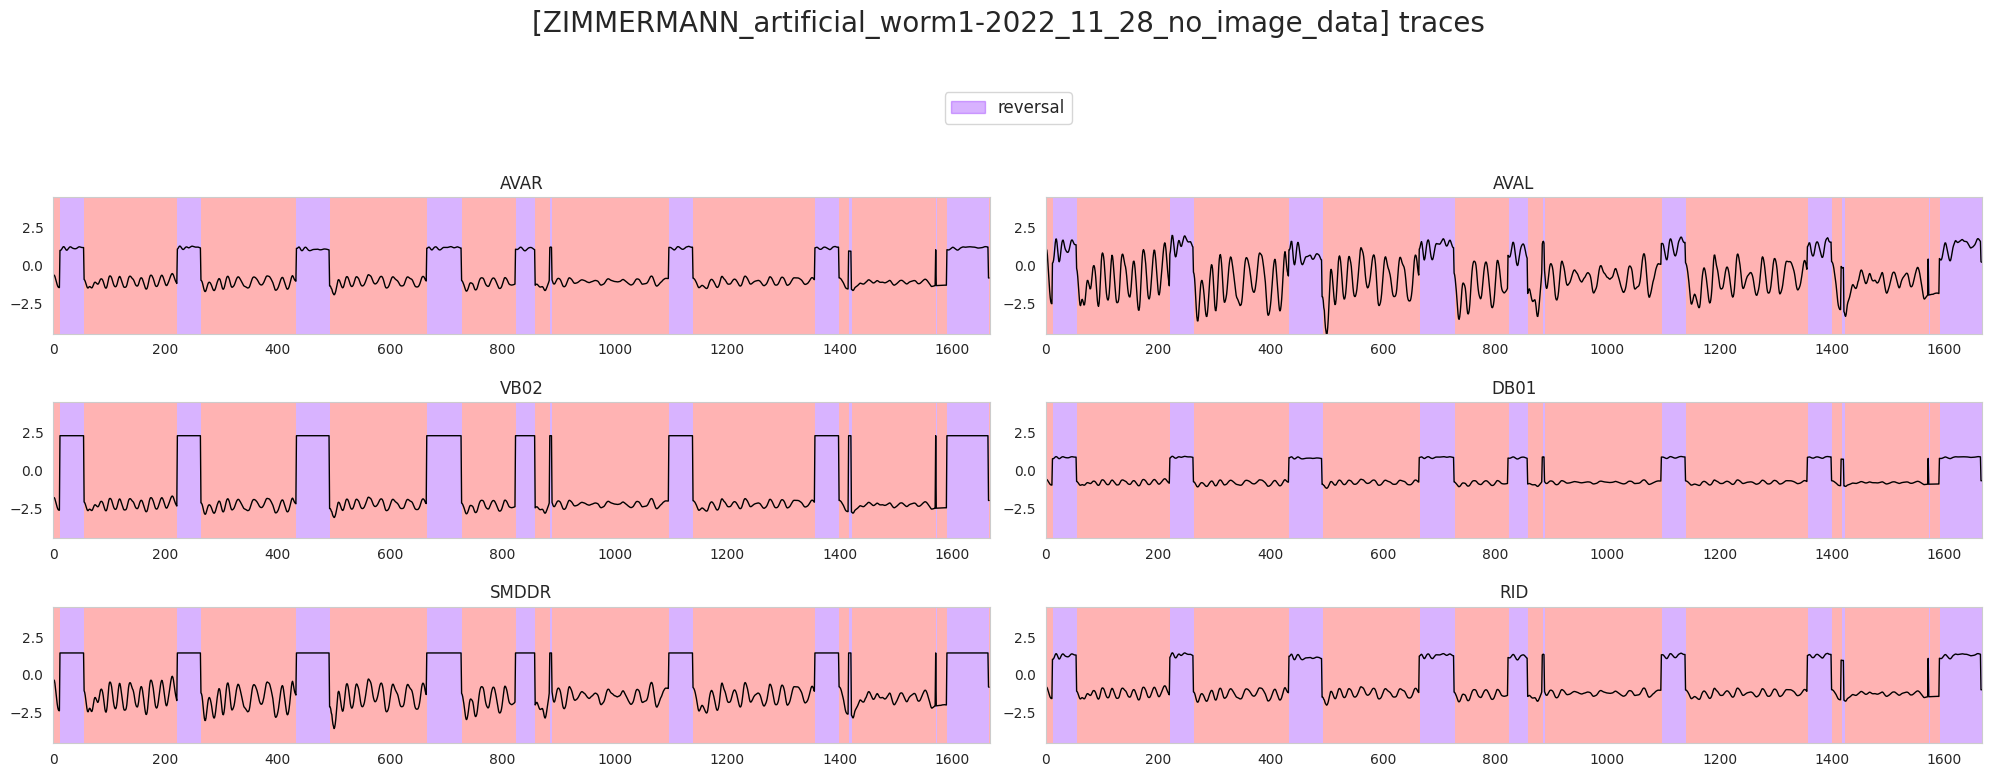

In [9]:
plot_utils.plot_traces(f'[{filename}] traces',
					   traces[selection_n],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2, ylimits=(-4.5, 4.5))

# sklearn CCA

In [10]:
X = traces.values
Y = discrete_states.values

X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_std[X_std == 0.0] = 1.0

Y_mean = Y.mean(axis=0)
Y_std = Y.std(axis=0)
Y_std[Y_std == 0.0] = 1.0

X_n = (X - X_mean) / X_std
Y_n = (Y - Y_mean) / Y_std

In [11]:
cca = CCA(n_components=dims, scale=True)
cca.fit(X, Y)

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/sklearn/cross_decomposition/_pls.py:104: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


,n_components,1
,scale,True
,max_iter,500
,tol,1e-06
,copy,True


In [12]:
X_l_h = X_n @ cca.x_rotations_
Y_l_h = Y_n @ cca.y_rotations_

X_l_h_t, Y_l_h_t = cca.transform(X, Y)

def norming(X_proj):
	X_proj = X_proj - np.mean(X_proj, axis=0)
	X_proj = X_proj / (np.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj
corr_a = np.array(norming(X_l_h).T @ norming(Y_l_h))

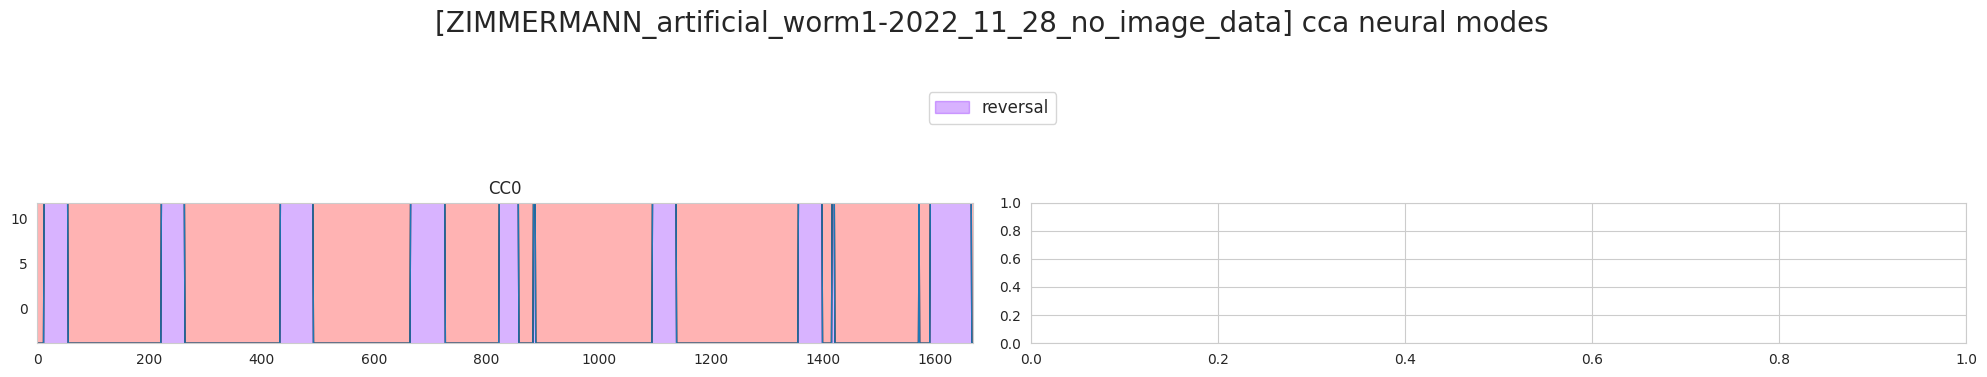

In [13]:
X_l_h_df = pd.DataFrame(data=X_l_h, columns=[f'CC{i}' for i in range(dims)])
X_l_h_t_df = pd.DataFrame(data=X_l_h_t, columns=[f'CC{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca neural modes',
					   [X_l_h_t_df, X_l_h_df],
					   discrete_states['REV'],
					   n_plots=dims, plots_per_row=2)  #, limits=(-1, 2)

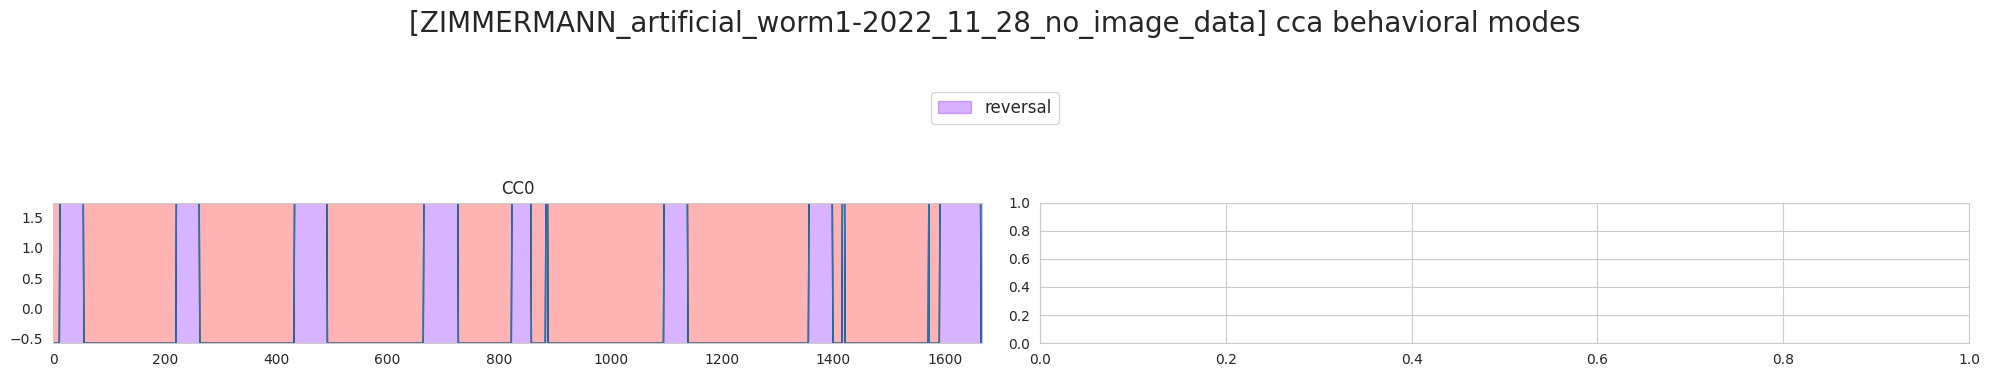

In [14]:
Y_l_h_df = pd.DataFrame(data=Y_l_h, columns=[f'CC{i}' for i in range(dims)])
Y_l_h_t_df = pd.DataFrame(data=Y_l_h_t, columns=[f'CC{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca behavioral modes',
					   [Y_l_h_t_df, Y_l_h_df],
					   discrete_states['REV'],
					   n_plots=dims, plots_per_row=2)  #, limits=(-1, 10)

In [15]:
X_rec_a = X_l_h @ cca.x_loadings_.T
Y_rec_a = Y_l_h @ cca.y_loadings_.T
X_rec_a, Y_rec_a = X_rec_a * X_std + X_mean, Y_rec_a * Y_std + Y_mean

X_rec_h_t, Y_rec_h_t = cca.inverse_transform(X_l_h_t, Y_l_h_t)

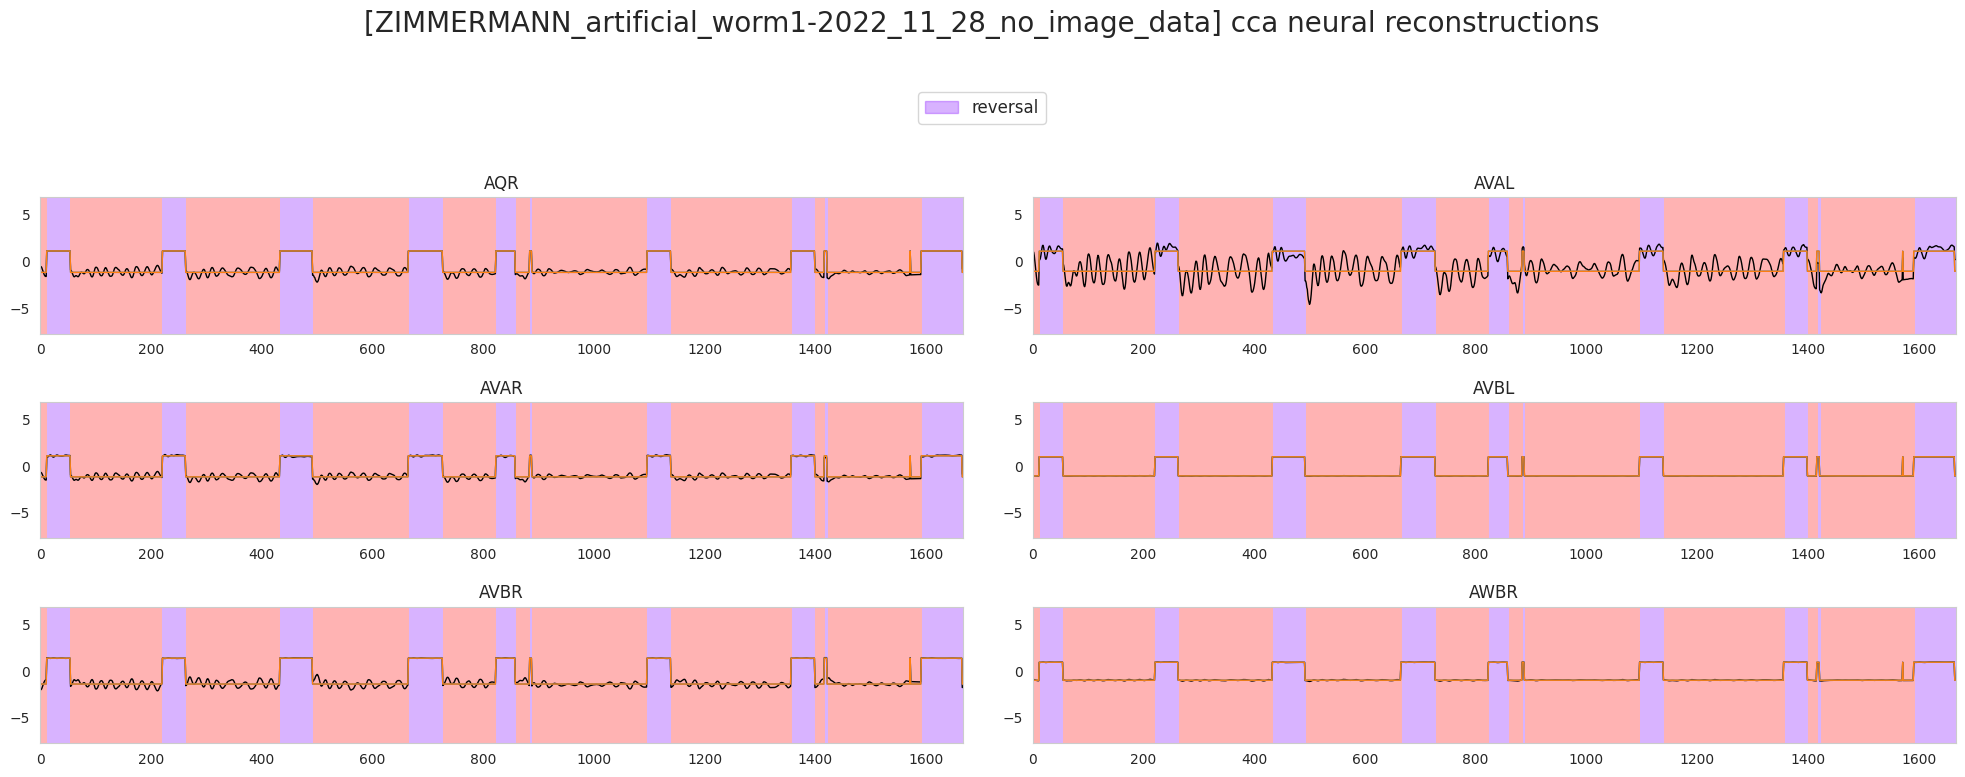

In [16]:
X_rec_h_df = pd.DataFrame(data=X_rec_a, columns=traces.columns)
X_rec_h_t_df = pd.DataFrame(data=X_rec_h_t, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca neural reconstructions',
					   [traces, X_rec_h_t_df, X_rec_h_df],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2)  #, limits=(-11, 5)

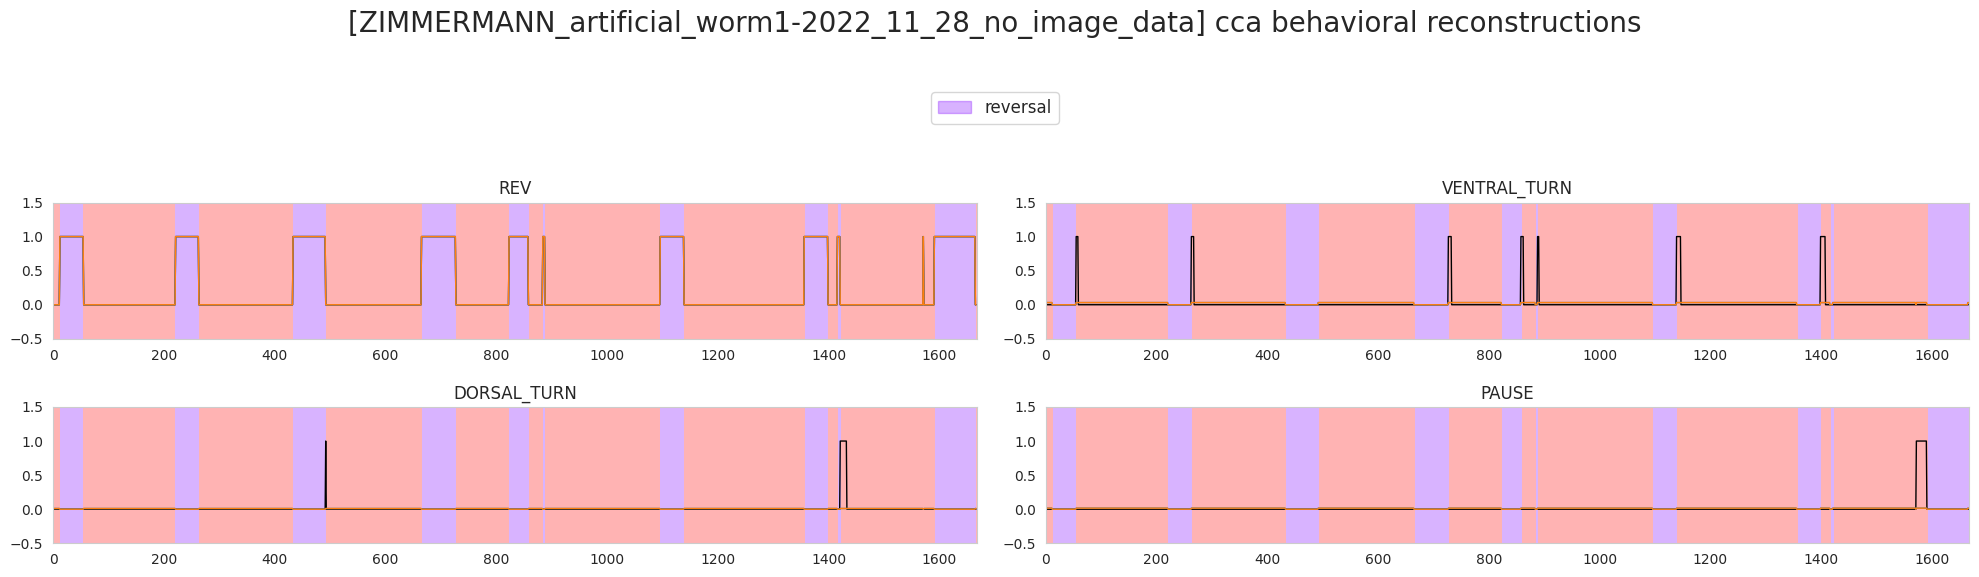

In [17]:
Y_rec_h_df = pd.DataFrame(data=Y_rec_a, columns=discrete_states.columns)
Y_rec_h_t_df = pd.DataFrame(data=Y_rec_h_t, columns=discrete_states.columns)

plot_utils.plot_traces(f'[{filename}] cca behavioral reconstructions',
					   [discrete_states, Y_rec_h_t_df, Y_rec_h_df],
					   discrete_states['REV'],
					   n_plots=len(selection_bhl), plots_per_row=2, ylimits=(-0.5, 1.5))

In [18]:
def get_reconstruction_matrix_x(X, X_proj):
	return np.linalg.inv(X_proj.T @ X_proj) @ X_proj.T @ X
	# return sp.linalg.pinv(U)

def get_reconstruction_matrix_y(Y, Y_proj):
	return np.linalg.inv(Y_proj.T @ Y_proj) @ Y_proj.T @ Y
	# return sp.linalg.pinv(V)

X_rec_h_cinv = np.matmul(X_l_h, get_reconstruction_matrix_x(X_n, X_l_h))
Y_rec_h_cinv = np.matmul(Y_l_h, get_reconstruction_matrix_y(Y_n, Y_l_h))
X_rec_h_cinv, Y_rec_h_cinv = X_rec_h_cinv * X_std + X_mean, Y_rec_h_cinv * Y_std + Y_mean

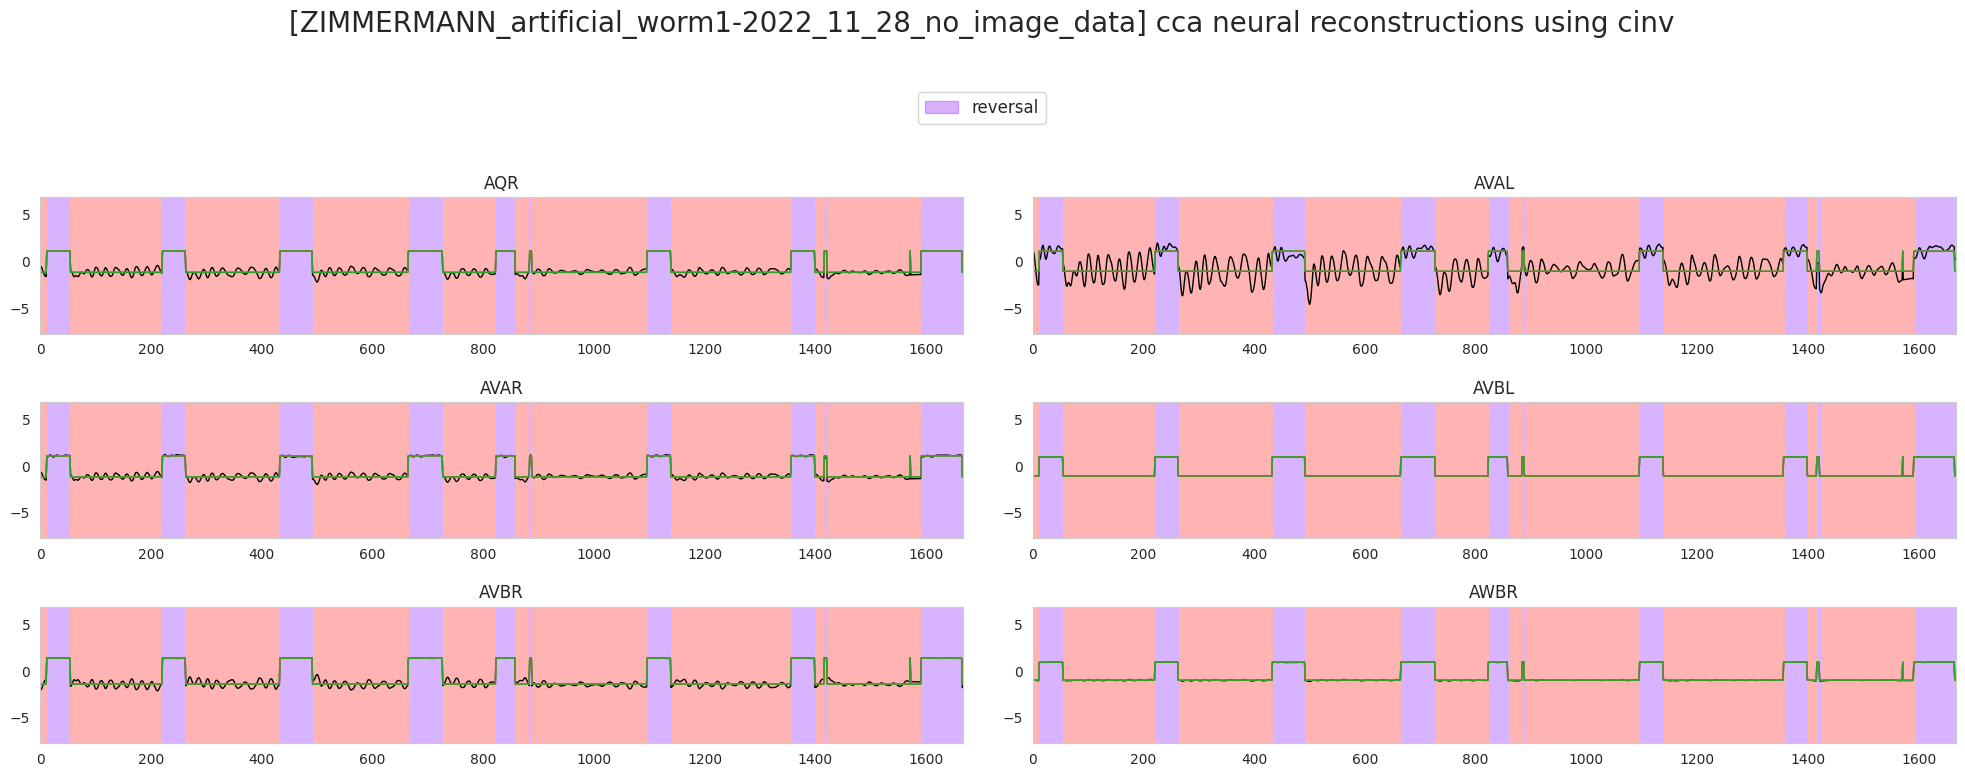

In [19]:
X_rec_h_cinv_df = pd.DataFrame(data=X_rec_h_cinv, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca neural reconstructions using cinv',
					   [traces, X_rec_h_t_df, X_rec_h_df, X_rec_h_cinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2)  #, limits=(-11, 5)

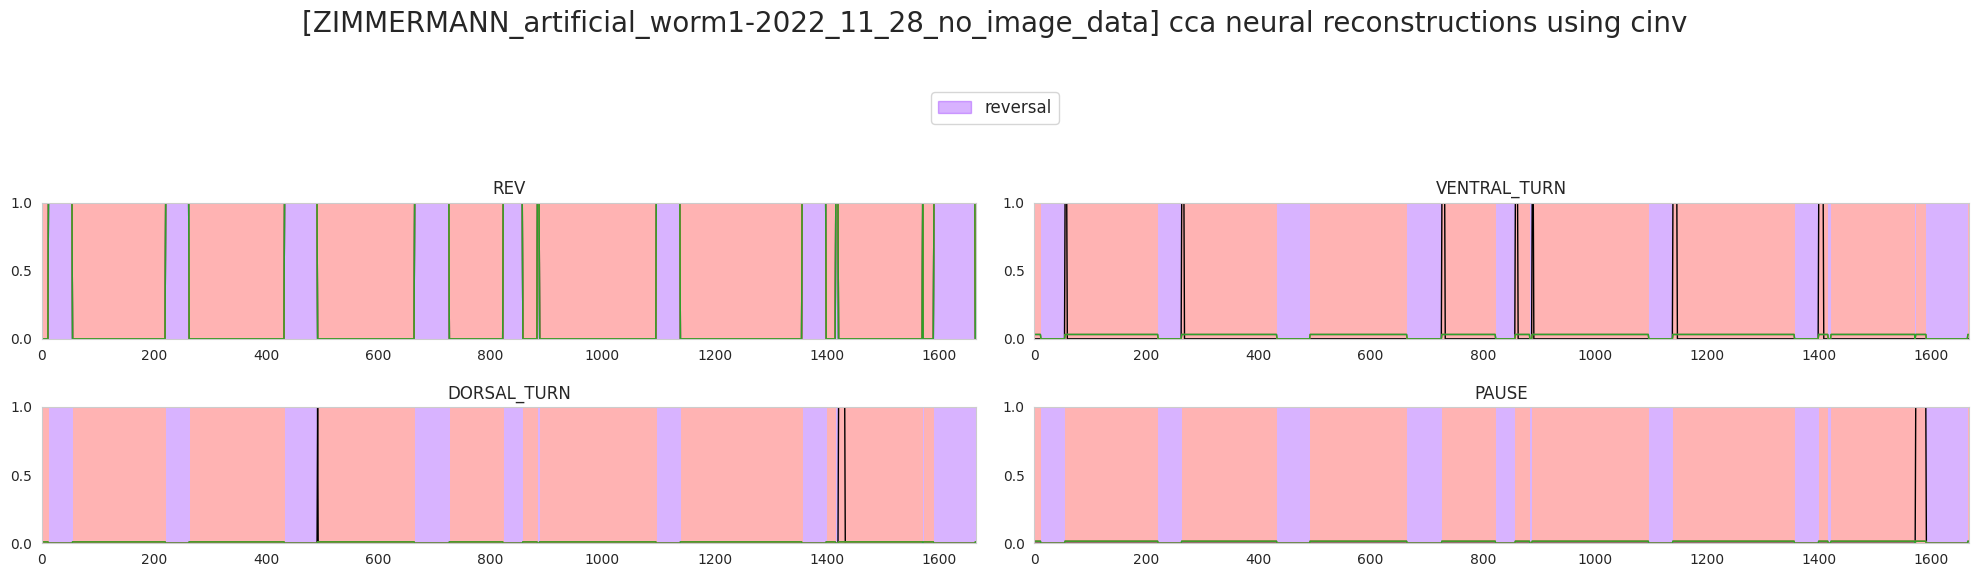

In [20]:
Y_rec_h_cinv_df = pd.DataFrame(data=Y_rec_h_cinv, columns=discrete_states.columns)

plot_utils.plot_traces(f'[{filename}] cca neural reconstructions using cinv',
					   [discrete_states, Y_rec_h_t_df, Y_rec_h_df, Y_rec_h_cinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_bhl), plots_per_row=2)  #, limits=(-11, 5)

# soft CCA

In [21]:
def init_params(seeds, shape_U, shape_V):
	return {
		'U': 1E-2 * jax.random.normal(seeds[0], shape_U),
		'V': 1E-2 * jax.random.normal(seeds[1], shape_V)
	}


def norming(X_proj):
	X_proj = X_proj - jnp.mean(X_proj, axis=0)
	X_proj = X_proj / (jnp.linalg.norm(X_proj, axis=0) + 1e-6)
	return X_proj


def cca_loss(X_proj, Y_proj):
	ccaunit_lambda, ccadiag_lambda = 0.5, 0.5

	corr = norming(X_proj).T @ norming(Y_proj)

	corr_diag = jnp.diag(jnp.diag(corr))
	corr_nondiag = corr - corr_diag

	return (ccaunit_lambda * jnp.mean(jnp.abs(corr_diag - jnp.eye(*corr_diag.shape)))
			+ ccadiag_lambda * jnp.mean(jnp.abs(corr_nondiag)))


def loss_fn(params, N, B_hl):
	U, V = params['U'], params['V']

	# manifold ================================
	N_man = N @ U
	B_hl_man = B_hl @ V

	man_loss = cca_loss(N_man, B_hl_man)
	# =========================================

	return man_loss

loss_fn_grad = jax.jit(jax.grad(loss_fn))


def update(opt_update, opt_state, params, N, B_hl):
	grads = loss_fn_grad(params, N, B_hl)
	params_updates, opt_state = opt_update(grads, opt_state, params)
	params_new = optax.apply_updates(params, params_updates)
	return params_new, opt_state, grads  # return grads for weight interpretation


def get_reconstruction_matrix_x(X, X_proj):
	return np.linalg.inv(X_proj.T @ X_proj) @ X_proj.T @ X  # magic (actually just analytical least-squares solution to reconstruction)
	# return np.linalg.inv(U.T @ U) @ U.T
	# return sp.linalg.pinv(U)


def get_reconstruction_matrix_y(Y, Y_proj):
	return np.linalg.inv(Y_proj.T @ Y_proj) @ Y_proj.T @ Y  # magic (actually just analytical least-squares solution to reconstruction)
	# return np.linalg.inv(V.T @ V) @ V.T
	# return sp.linalg.pinv(V)


def train_num_cca(N, B_hl, n_dimensions):
	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1)

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]

	max_epochs = 10000
	optimizer = optax.adam(1e-3)

	params = init_params(seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions))
	opt_state = optimizer.init(params)

	losses_tr = [loss_fn(params, N, B_hl).item()]
	for epoch in range(max_epochs):
		params, opt_state, __grad = update(optimizer.update, opt_state, params, N, B_hl)
		loss_tr = loss_fn(params, N, B_hl).item()
		losses_tr.append(loss_tr)

	U, V = params['U'], params['V']
	N_man = N @ U
	B_hl_man = B_hl @ V

	N_rec = N_man @ get_reconstruction_matrix_x(N, N_man)
	N_res = N - N_rec
	B_hl_rec = B_hl_man @ get_reconstruction_matrix_y(B_hl, B_hl_man)

	return losses_tr, params, np.array(N_man), np.array(B_hl_man), np.array(N_rec), np.array(B_hl_rec), np.array(N_res)

In [22]:
losses, params, X_l_s, Y_l_s, X_rec_s_cinv, Y_rec_s_cinv, X_res_n = train_num_cca(X_n, Y_n, dims)
corr_n = np.array(norming(X_l_s).T @ norming(Y_l_s) / norming(X_l_s).shape[0])

X_rec_s_cinv, Y_rec_s_cinv = X_rec_s_cinv * X_std + X_mean, Y_rec_s_cinv * Y_std + Y_mean

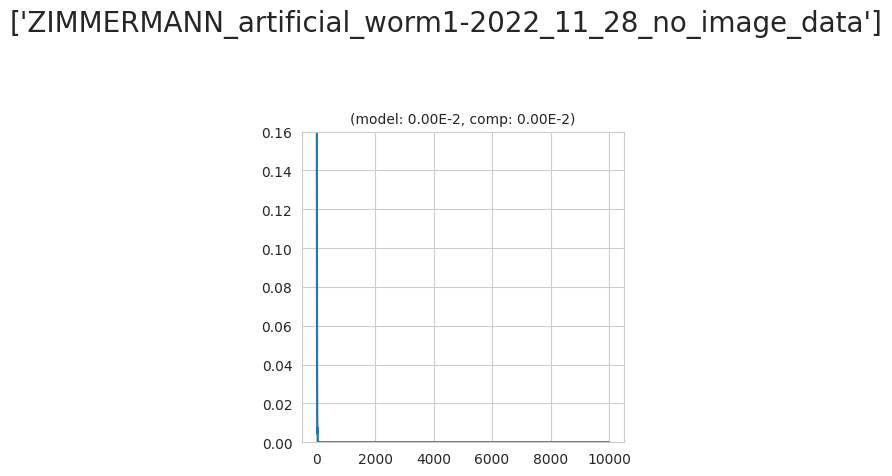

In [23]:
losses = np.array(losses)
y_limits = (losses.min(), losses.min() + (losses.max() - losses.min()) * 0.2)
plot_utils.plot_losses_splits([filename], 'soft cca', [np.array([losses])], [np.array([losses])], n_plots=1, plots_per_row=1, ylimits=y_limits)

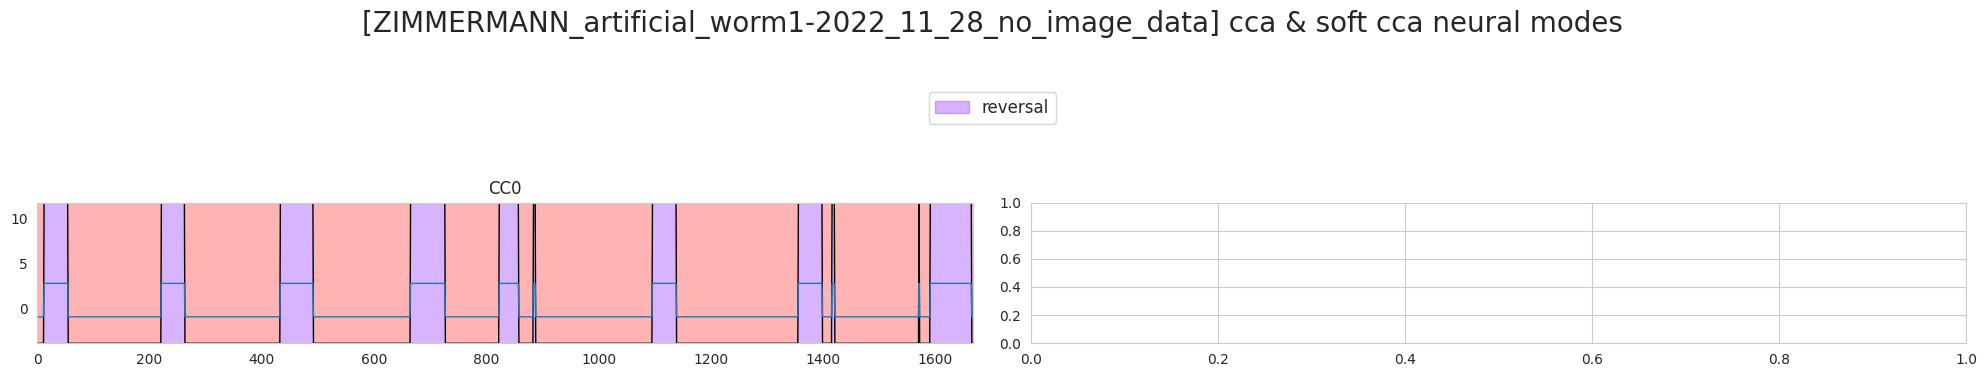

In [24]:
X_l_s_df = pd.DataFrame(data=X_l_s, columns=[f'CC{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca & soft cca neural modes',
					   [X_l_h_df, X_l_s_df],
					   discrete_states['REV'],
					   n_plots=dims, plots_per_row=2)  #, limits=(-1, 2)

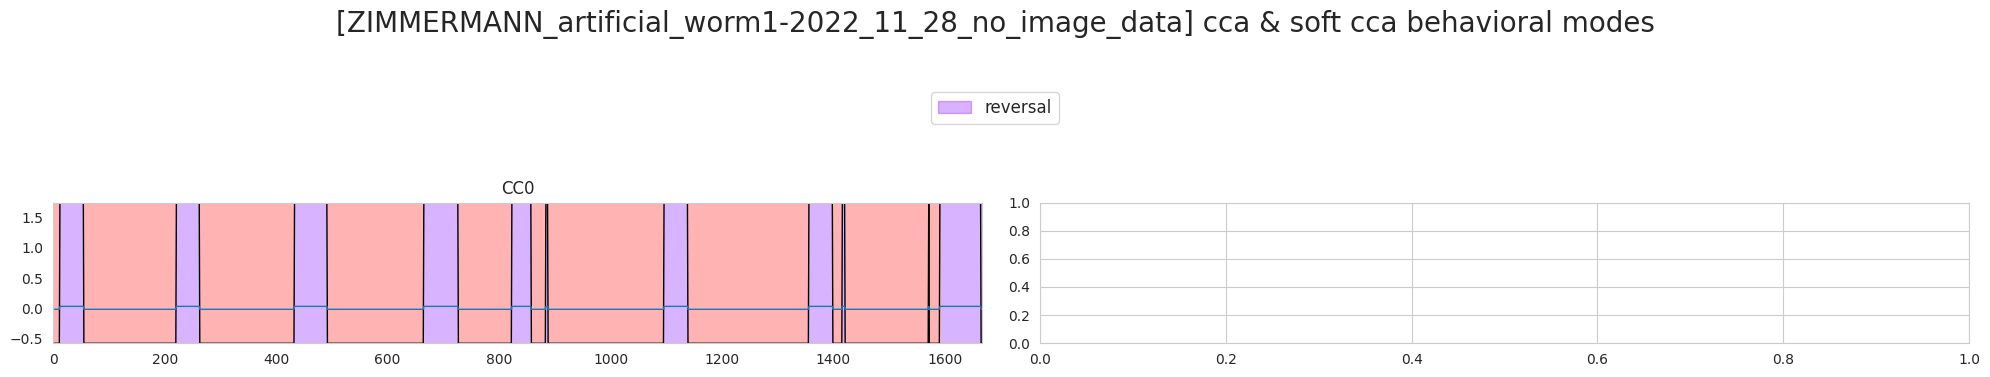

In [25]:
Y_l_s_df = pd.DataFrame(data=Y_l_s, columns=[f'CC{i}' for i in range(dims)])

plot_utils.plot_traces(f'[{filename}] cca & soft cca behavioral modes',
					   [Y_l_h_df, Y_l_s_df],
					   discrete_states['REV'],
					   n_plots=dims, plots_per_row=2)  #, limits=(-1, 2)

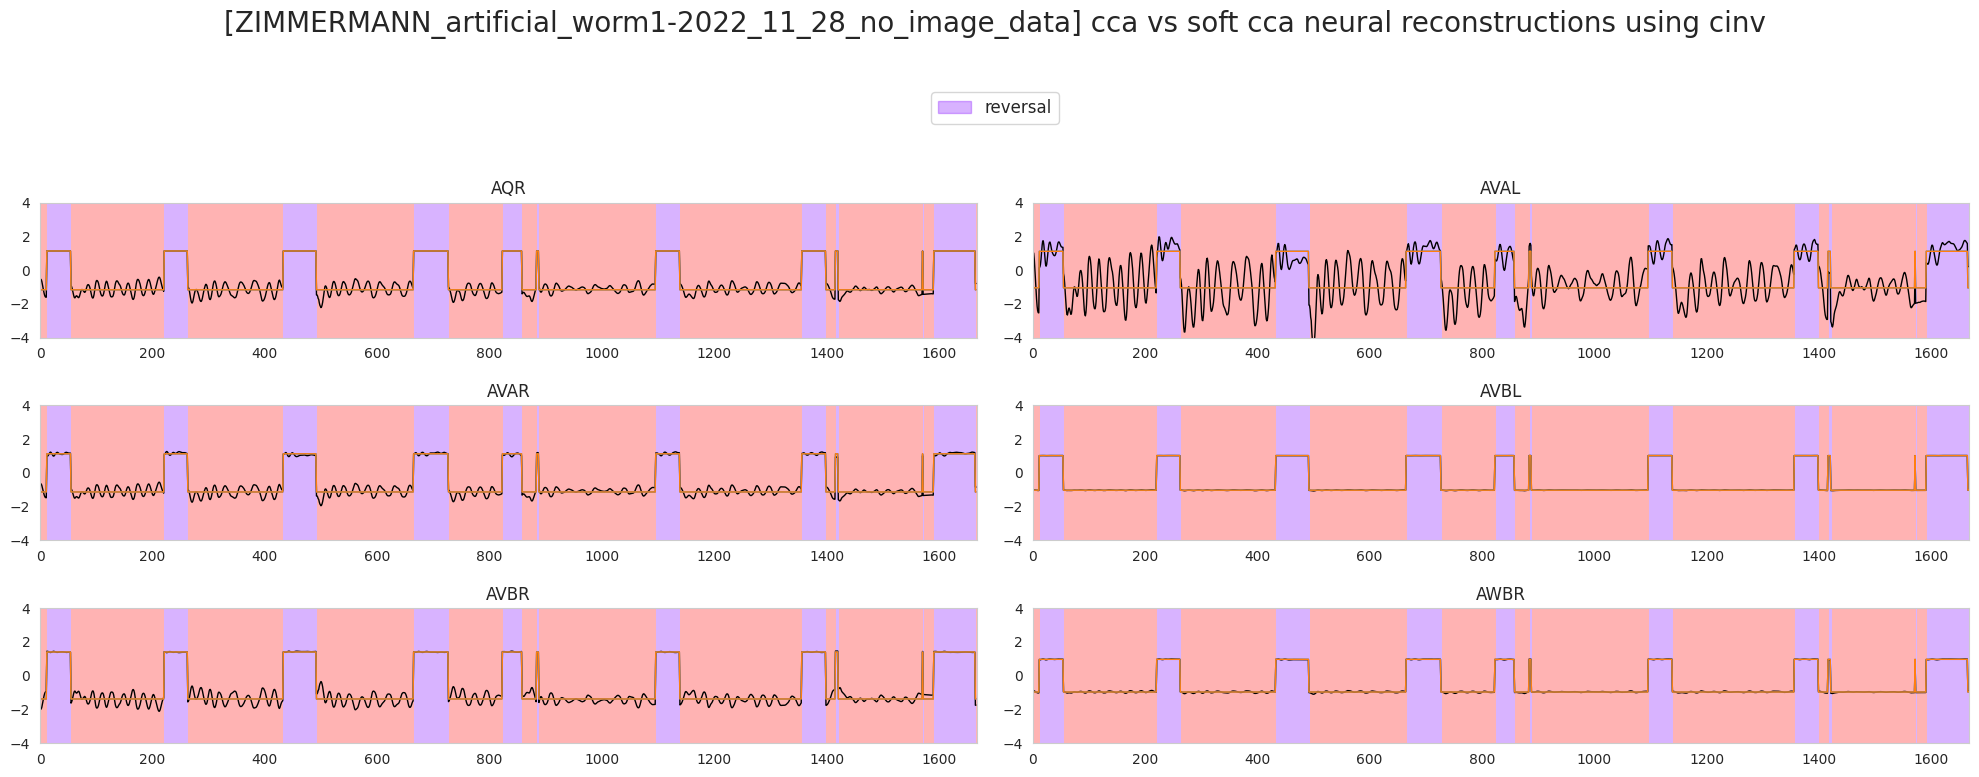

In [31]:
X_rec_s_cinv_df = pd.DataFrame(data=X_rec_s_cinv, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural reconstructions using cinv',
					   [traces, X_rec_h_t_df, X_rec_s_cinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2, ylimits=(-4, 4))

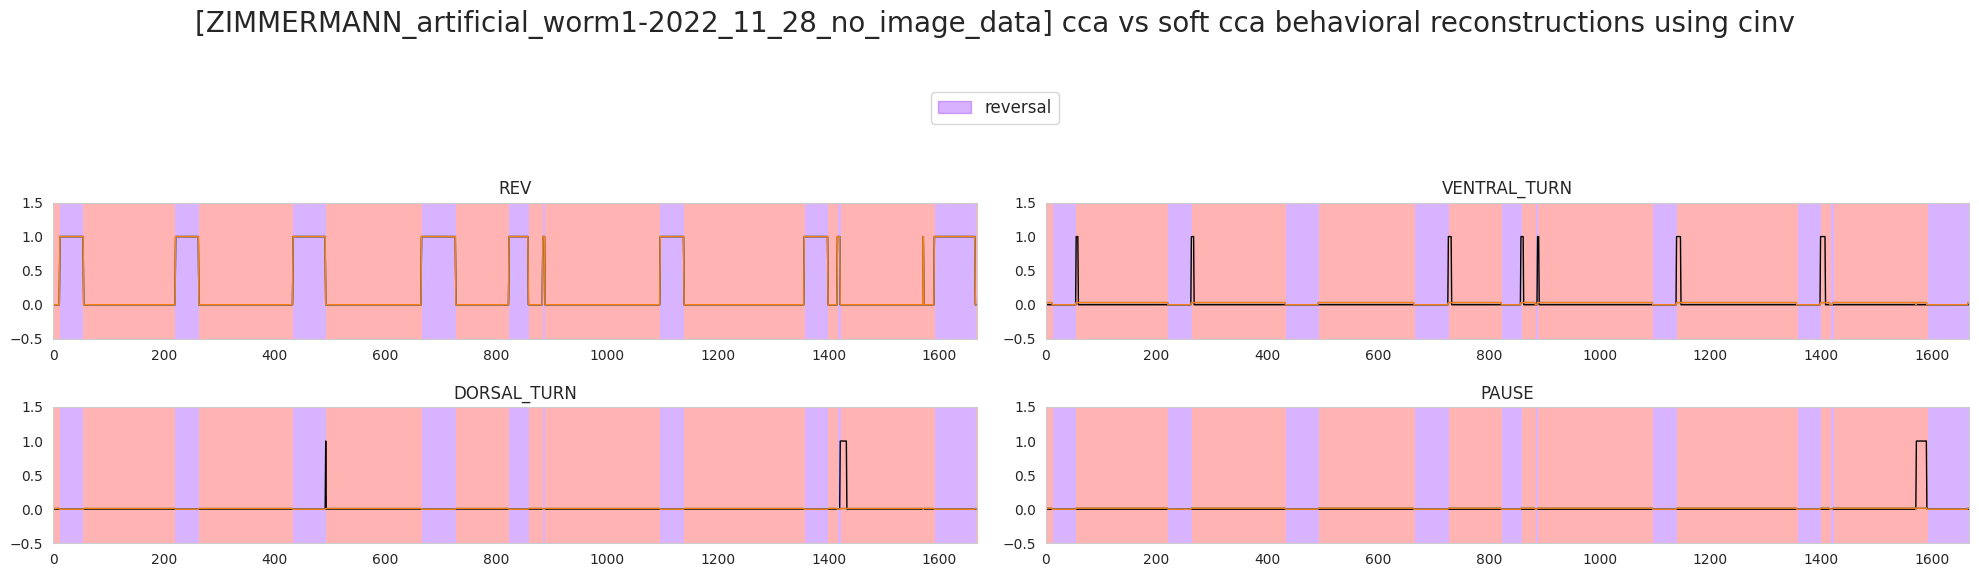

In [27]:
Y_rec_s_cinv_df = pd.DataFrame(data=Y_rec_s_cinv, columns=discrete_states.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca behavioral reconstructions using cinv',
					   [discrete_states, Y_rec_h_t_df, Y_rec_s_cinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_bhl), plots_per_row=2, ylimits=(-0.5, 1.5))

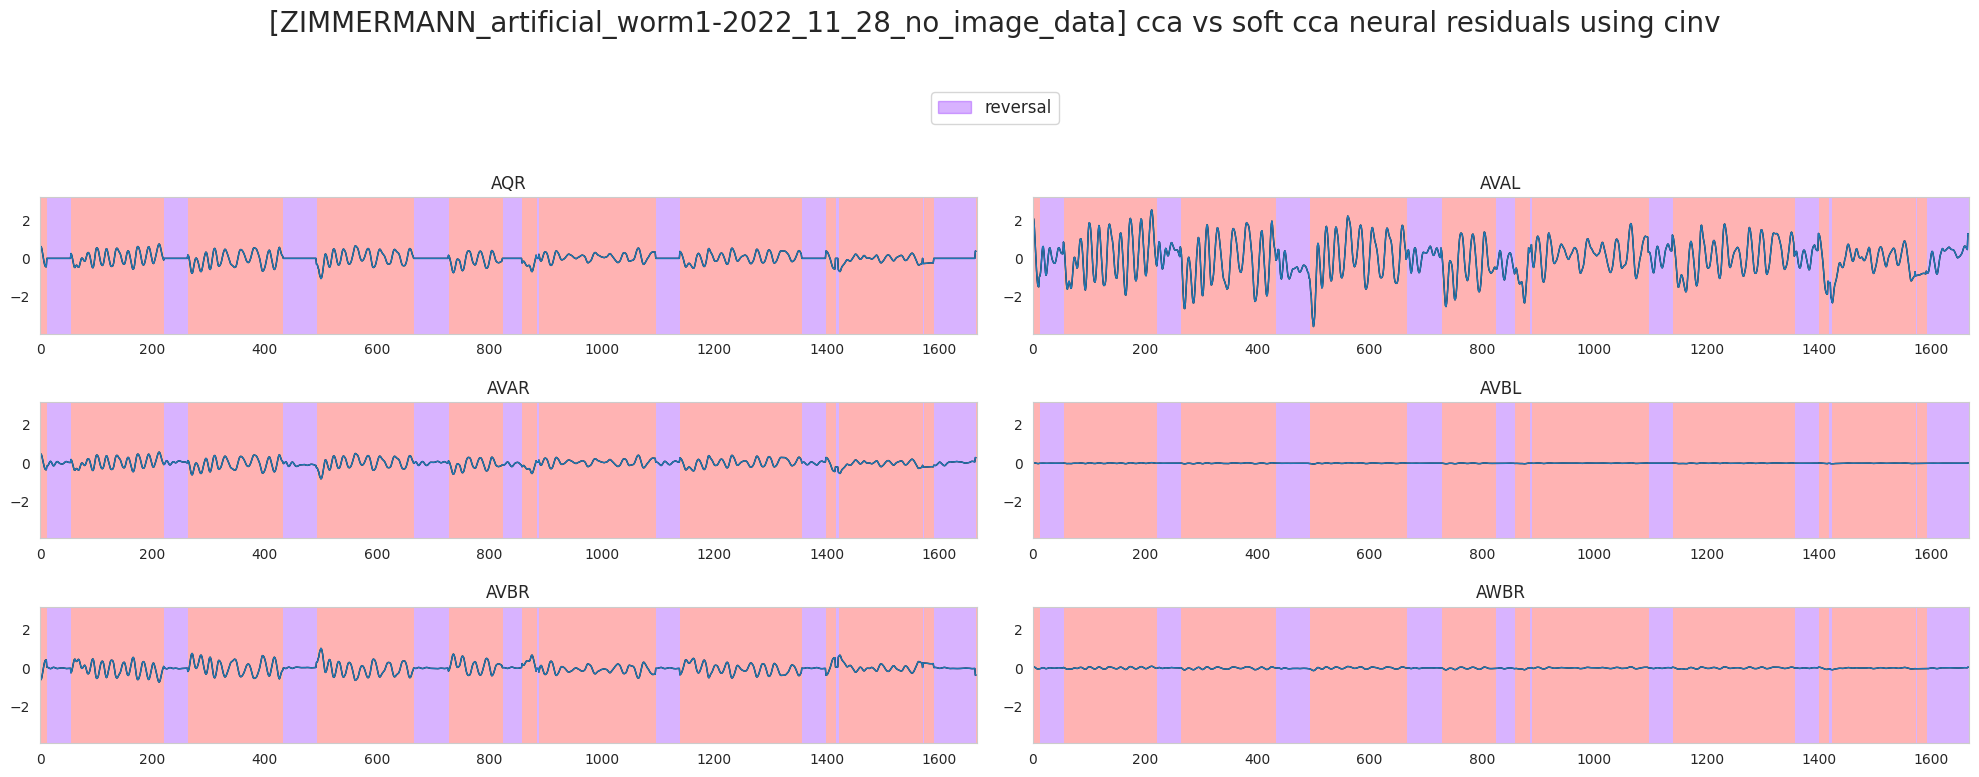

In [28]:
X_res_h_t_df = pd.DataFrame(data=X - X_rec_h_t, columns=traces.columns)
X_res_s_cinv_df = pd.DataFrame(data=X - X_rec_s_cinv, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural residuals using cinv',
					   [X_res_h_t_df, X_res_s_cinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2)  #, limits=(-14, 7)

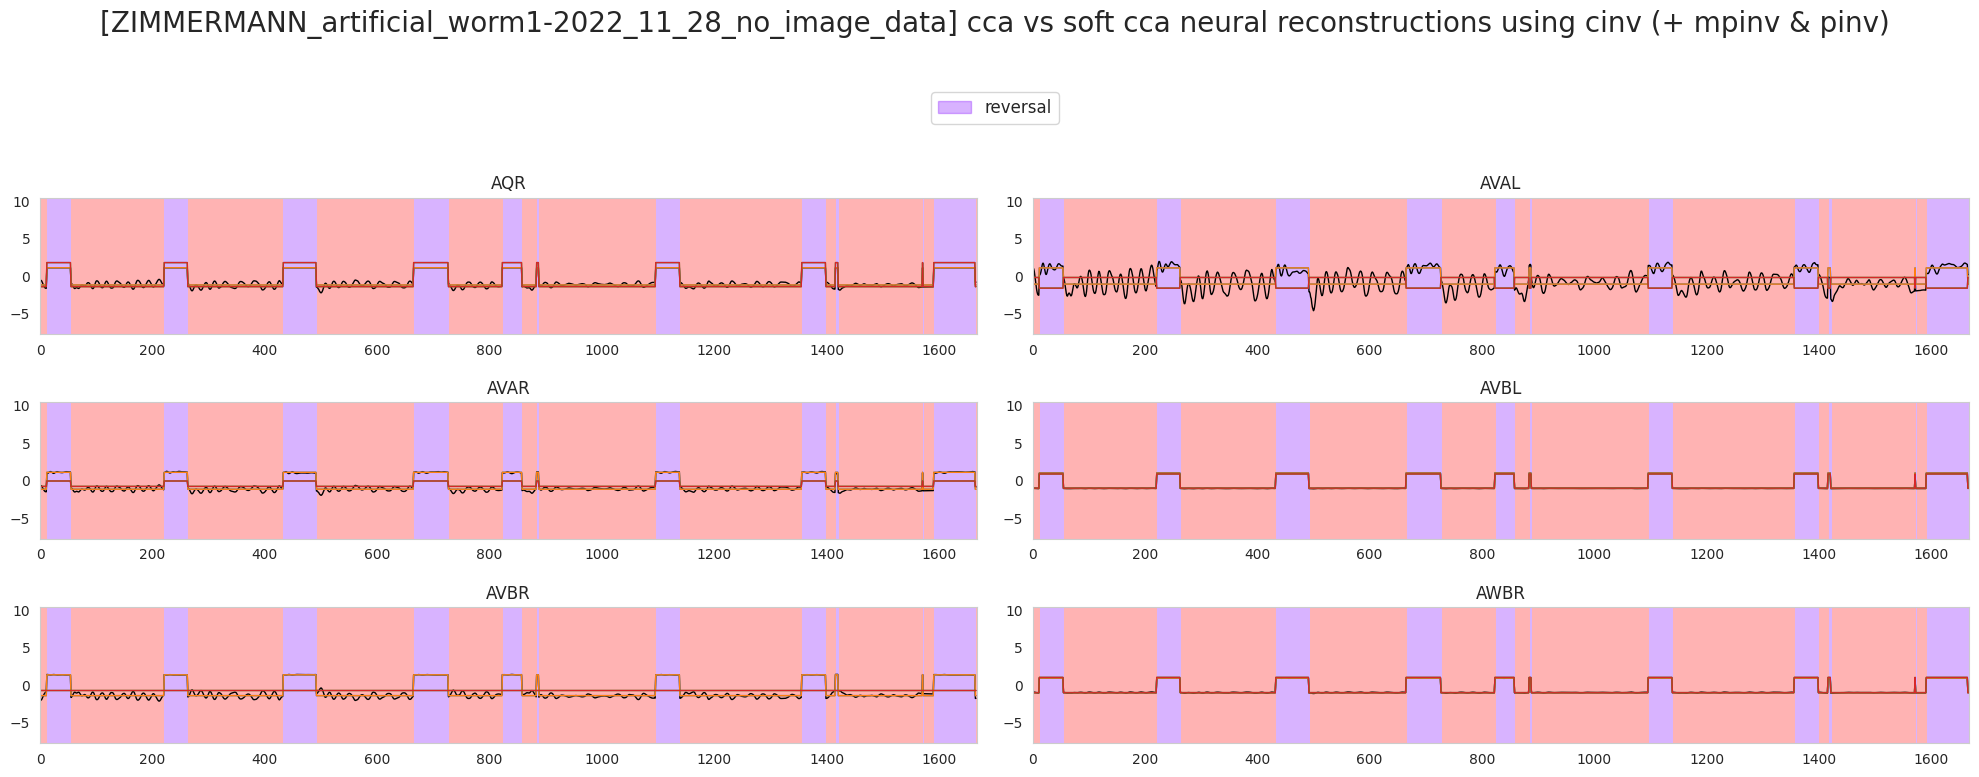

In [29]:
U = params['U']

X_rec_s_mpinv = X_l_s @ np.linalg.inv(U.T @ U) @ U.T * X_std + X_mean
X_rec_s_mpinv_df = pd.DataFrame(data=X_rec_s_mpinv, columns=traces.columns)

X_rec_s_pinv = X_l_s @ np.linalg.pinv(U) * X_std + X_mean
X_rec_s_pinv_df = pd.DataFrame(data=X_rec_s_pinv, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural reconstructions using cinv (+ mpinv & pinv)',
					   [traces, X_rec_h_t_df, X_rec_s_cinv_df, X_rec_s_mpinv_df, X_rec_s_pinv_df],
					   discrete_states['REV'],
					   n_plots=len(selection_n), plots_per_row=2)  #, limits=(-14, 7)

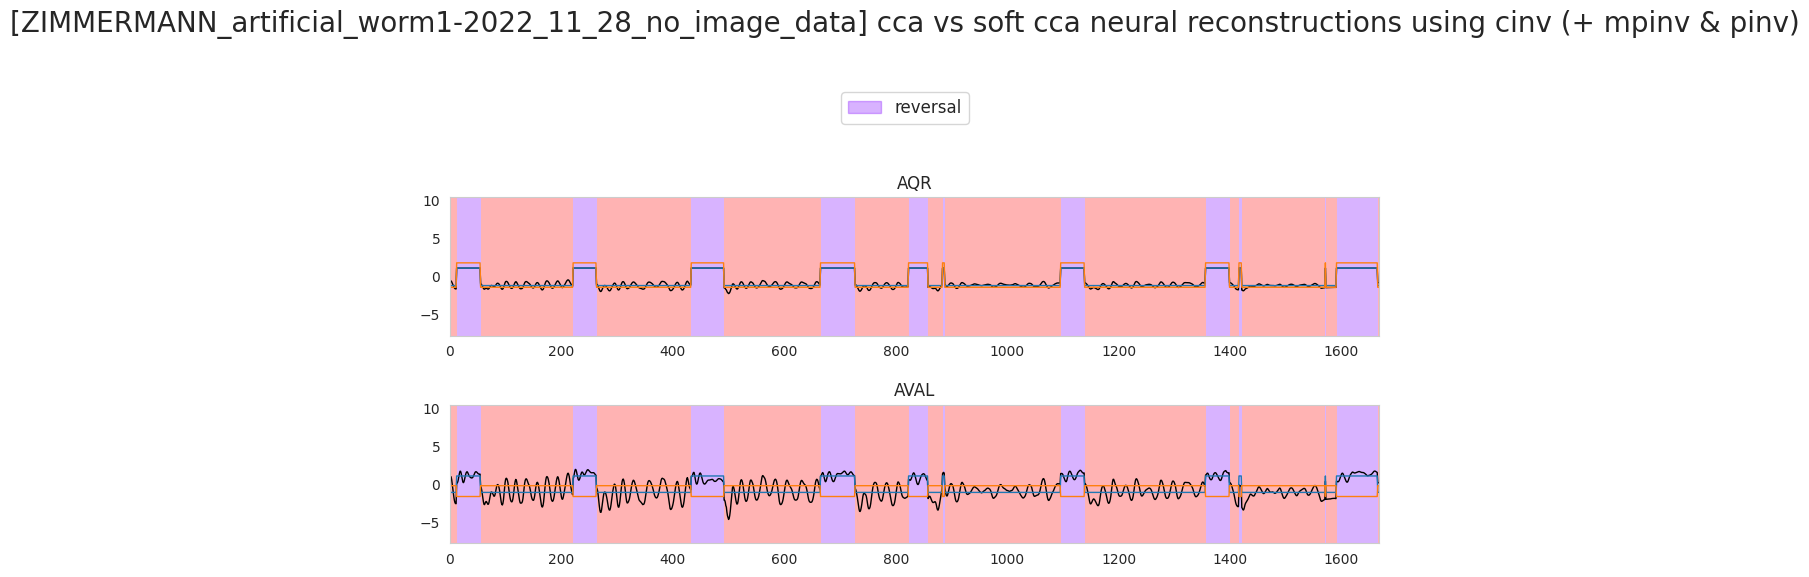

In [30]:
U = params['U']

X_rec_s_mpinv = X_l_s @ np.linalg.inv(U.T @ U) @ U.T * X_std + X_mean
X_rec_s_mpinv_df = pd.DataFrame(data=X_rec_s_mpinv, columns=traces.columns)

X_rec_s_pinv = X_l_s @ np.linalg.pinv(U) * X_std + X_mean
X_rec_s_pinv_df = pd.DataFrame(data=X_rec_s_pinv, columns=traces.columns)

plot_utils.plot_traces(f'[{filename}] cca vs soft cca neural reconstructions using cinv (+ mpinv & pinv)',
					   [traces, X_rec_s_cinv_df, X_rec_s_pinv_df],
					   discrete_states['REV'],
					   keys=['AQR', 'AVAL'],
					   n_plots=2, plots_per_row=1, ylimits=None, save_name='aval')  #, limits=(-14, 7)